# House Prices: EDA and preprocessing
## 1. Project objective
Explore the Kaggle House Prices data and prepare features for a future model. **We do not train a prediction model in this notebook.** EDA means exploratory data analysis: inspecting tables and plots to understand the data.

`SalePrice` is the target (the value we might predict later). The other useful columns are features. `Id` identifies a row and must not be a feature.

Run cells from top to bottom with the notebook opened from the project folder containing `data/`. We only read source files; all changes happen in memory. Later, we split the labeled data before fitting preprocessing. Medians, modes, and encoding categories are learned only from the training split. The earlier full-data EDA is descriptive; do not use it to tune features against the held-out validation set.

## 2. Importing libraries
pandas handles tables, NumPy handles numerical arrays, and Matplotlib/Seaborn draw plots. scikit-learn provides splitting and preprocessing tools. A preprocessing pipeline learns cleaning rules; it is not a prediction model.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 15)

## 3. Loading train.csv and test.csv
Kaggle's `train.csv` contains known prices. Its `test.csv` has no `SalePrice`; it is different from our validation split.

We use the supplied data dictionary to interpret `NA` and `None`. Empty fields, numerical `NA` tokens, and categorical `NA` tokens without a documented absence meaning become missing values (`NaN`). `MasVnrType` uses `None` for no veneer, so its `NA` is unknown.

For basement, garage, pool, and fireplace attributes, retain an absence token only when the related area/count is zero. A positive or unknown measurement means absence is not confirmed, so a missing attribute remains unknown. These fixed rules use each house's own features and learn no statistics. Section 10 prints the relevant dictionary entries for review.

No files are rewritten. The sample submission is not needed until a later prediction stage.

In [2]:
data_dir = Path("data")
required_files = ["train.csv", "test.csv", "data_description.txt", "sample_submission.csv"]
for filename in required_files:
    assert (data_dir / filename).is_file(), f"Missing data/{filename}. Open/run from the housingml folder."

train_df = pd.read_csv("data/train.csv", keep_default_na=False, na_values=[""])
test_df = pd.read_csv("data/test.csv", keep_default_na=False, na_values=[""])
# In numerical columns, NA is an unknown number, not a category.
# These columns are numerical according to the data dictionary.
numeric_with_na = [
    "LotFrontage", "MasVnrArea", "GarageYrBlt", "BsmtFinSF1", "BsmtFinSF2",
    "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath", "GarageCars", "GarageArea",
]
for frame in [train_df, test_df]:
    for column in numeric_with_na:
        frame[column] = pd.to_numeric(frame[column].replace("NA", np.nan), errors="raise")

# NA is meaningful only for columns where the dictionary defines absence.
absence_columns = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature", "MasVnrType",
]
# Check related measurements before trusting an absence token.
presence_measure = {
    **{c: "TotalBsmtSF" for c in ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]},
    **{c: "GarageArea" for c in ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]},
    "PoolQC": "PoolArea", "FireplaceQu": "Fireplaces",
}
for frame in [train_df, test_df]:
    for column in frame.select_dtypes(exclude="number").columns:
        values = frame[column].astype(object).where(frame[column].notna(), np.nan)
        if column not in absence_columns or column == "MasVnrType":
            # MasVnrType uses None for absence; its NA tokens are unknown.
            values = values.replace("NA", np.nan)
        elif column in presence_measure:
            confirmed_absence = frame[presence_measure[column]].eq(0)
            values = values.mask(values.eq("NA") & ~confirmed_absence, np.nan)
        frame[column] = values

assert "SalePrice" in train_df and "SalePrice" not in test_df
assert set(train_df.columns) - {"SalePrice"} == set(test_df.columns)
print("Dataset files found and loaded. Originals remain unchanged.")

Dataset files found and loaded. Originals remain unchanged.


## 4. Inspecting shape, head, info, and descriptive statistics
`shape` gives (rows, columns); `head()` shows the first rows; `info()` shows data types and non-missing counts. `describe()` summarizes numeric values or categorical frequencies. A numeric storage type does not always mean a measurement: `MSSubClass` is a category code.

In [3]:
print("Train shape:", train_df.shape)
print("Kaggle test shape:", test_df.shape)
print("Train preview:")
display(train_df.head())
print("Test preview:")
display(test_df.head())
print("Train information:")
train_df.info()
print("Test information:")
test_df.info()
print("Train numerical statistics:")
display(train_df.describe().T)
print("Test numerical statistics:")
display(test_df.describe().T)
print("Train categorical statistics:")
display(train_df.select_dtypes(exclude="number").describe().T)
print("Test categorical statistics:")
display(test_df.select_dtypes(exclude="number").describe().T)

Train shape: (1460, 81)
Kaggle test shape: (1459, 80)
Train preview:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,...,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NA,...,NA,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NA,...,NA,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NA,...,NA,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NA,...,NA,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NA,...,NA,0,12,2008,WD,Normal,250000


Test preview:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,...,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NA,...,MnPrv,NA,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NA,...,NA,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NA,...,MnPrv,NA,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NA,...,NA,NA,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NA,...,NA,NA,0,1,2010,WD,Normal


Train information:
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          1460 non-null   object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  

...

,count,mean,std,min,25%,50%,75%,max
Id,1459.0,2190.000000,421.321334,1461.0,1825.50,2190.0,2554.50,2919.0
MSSubClass,1459.0,57.378341,42.746880,20.0,20.00,50.0,70.00,190.0
LotFrontage,1232.0,68.580357,22.376841,21.0,58.00,67.0,80.00,200.0
LotArea,1459.0,9819.161069,4955.517327,1470.0,7391.00,9399.0,11517.50,56600.0
OverallQual,1459.0,6.078821,1.436812,1.0,5.00,6.0,7.00,10.0
OverallCond,1459.0,5.553804,1.113740,1.0,5.00,5.0,6.00,9.0
YearBuilt,1459.0,1971.357779,30.390071,1879.0,1953.00,1973.0,2001.00,2010.0
YearRemodAdd,1459.0,1983.662783,21.130467,1950.0,1963.00,1992.0,2004.00,2010.0
MasVnrArea,1444.0,100.709141,177.625900,0.0,0.00,0.0,164.00,1290.0
BsmtFinSF1,1458.0,439.203704,455.268042,0.0,0.00,350.5,753.50,4010.0


Train categorical statistics:


,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,1460,3,NA,1369
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


Test categorical statistics:


,count,unique,top,freq
MSZoning,1455,5,RL,1114
Street,1459,2,Pave,1453
Alley,1459,3,NA,1352
LotShape,1459,4,Reg,934
LandContour,1459,4,Lvl,1311
Utilities,1457,1,AllPub,1457
LotConfig,1459,5,Inside,1081
LandSlope,1459,3,Gtl,1396
Neighborhood,1459,25,NAmes,218
Condition1,1459,9,Norm,1251


## 5. Understanding the SalePrice target distribution
A histogram shows how common different prices are. A long right tail means a few houses are much more expensive. `log1p` compresses the tail for comparison only; we keep the original target unchanged.

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

SalePrice skewness: 1.883


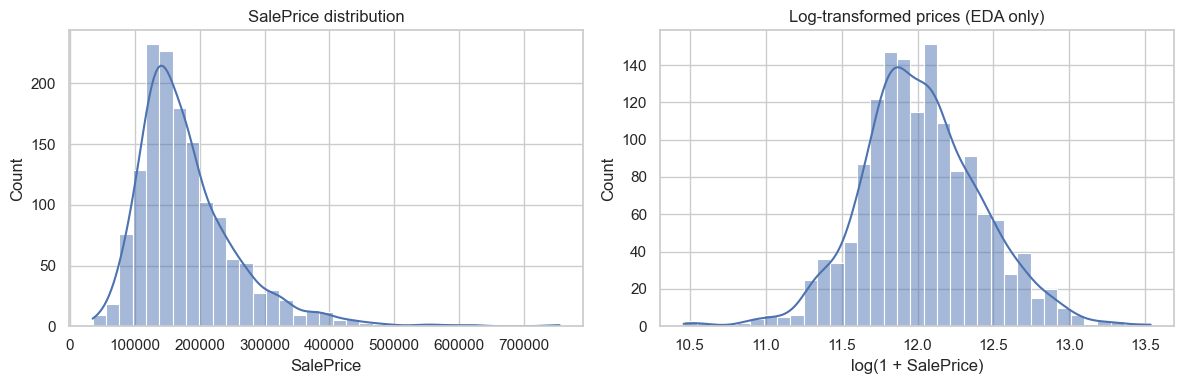

In [4]:
assert train_df["SalePrice"].notna().all()
assert (train_df["SalePrice"] > 0).all()
display(train_df["SalePrice"].describe())
print("SalePrice skewness:", round(train_df["SalePrice"].skew(), 3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_df["SalePrice"], bins=35, kde=True, ax=axes[0])
axes[0].set_title("SalePrice distribution")
sns.histplot(np.log1p(train_df["SalePrice"]), bins=35, kde=True, ax=axes[1])
axes[1].set_title("Log-transformed prices (EDA only)")
axes[1].set_xlabel("log(1 + SalePrice)")
plt.tight_layout()
plt.show()

## 6. Missing-value counts and percentages
Count unknown values separately for each dataset after dictionary-based interpretation. Percentages make columns easier to compare. Documented absence tokens retained during loading are categories and are not included in unknown-value counts; we count them separately below. Section 10 reviews their definitions.

In [5]:
def missing_summary(frame):
    counts = frame.isna().sum()
    return pd.DataFrame({"missing_count": counts,
                         "missing_percent": (100 * counts / len(frame)).round(2)})         .sort_values("missing_count", ascending=False)

train_missing = missing_summary(train_df)
test_missing = missing_summary(test_df)
print("Train columns with unknown values:")
display(train_missing.loc[train_missing["missing_count"] > 0])
print("Test columns with unknown values:")
display(test_missing.loc[test_missing["missing_count"] > 0])
for name, frame in [("train", train_df), ("test", test_df)]:
    counts = frame.select_dtypes(exclude="number").isin(["NA", "None"]).sum()
    print(name, "literal NA/None category counts:")
    display(counts[counts > 0].sort_values(ascending=False).to_frame("count"))

Train columns with unknown values:


,missing_count,missing_percent
LotFrontage,259,17.74
GarageYrBlt,81,5.55
MasVnrArea,8,0.55
MasVnrType,8,0.55
BsmtExposure,1,0.07
BsmtFinType2,1,0.07
Electrical,1,0.07


Test columns with unknown values:


,missing_count,missing_percent
LotFrontage,227,15.56
GarageYrBlt,78,5.35
MasVnrType,16,1.10
MasVnrArea,15,1.03
BsmtCond,4,0.27
MSZoning,4,0.27
BsmtQual,3,0.21
BsmtExposure,3,0.21
PoolQC,3,0.21
BsmtFullBath,2,0.14


train literal NA/None category counts:


,count
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,864
FireplaceQu,690
GarageQual,81
GarageType,81
GarageFinish,81
GarageCond,81


test literal NA/None category counts:


,count
PoolQC,1453
MiscFeature,1408
Alley,1352
Fence,1169
MasVnrType,878
FireplaceQu,730
GarageQual,76
GarageType,76
GarageFinish,76
GarageCond,76


## 7. Duplicate and ID checks
Check repeated rows and repeated IDs before making changes. Excluding `Id` helps reveal otherwise identical records. We report duplicates rather than automatically deleting houses: similar houses may be legitimate separate sales. Original IDs remain available for later matching to predictions.

In [6]:
for name, frame in [("train", train_df), ("test", test_df)]:
    print(f"{name}: full duplicate rows = {frame.duplicated().sum()}")
    print(f"{name}: duplicates excluding Id = {frame.drop(columns='Id').duplicated().sum()}")
    print(f"{name}: missing IDs = {frame['Id'].isna().sum()}, duplicate IDs = {frame['Id'].duplicated().sum()}")
    assert frame["Id"].notna().all() and frame["Id"].is_unique
print("IDs shared between train and test:", len(set(train_df["Id"]) & set(test_df["Id"])))

train: full duplicate rows = 0
train: duplicates excluding Id = 0
train: missing IDs = 0, duplicate IDs = 0
test: full duplicate rows = 0
test: duplicates excluding Id = 0
test: missing IDs = 0, duplicate IDs = 0
IDs shared between train and test: 0


## 8. Numerical and categorical feature analysis
Numerical features describe measurements or counts. Categorical features describe groups. We treat `MSSubClass` as a category, following the description. Ratings such as `OverallQual` remain numeric in this introductory workflow. These are fixed interpretation choices, not rules learned from validation data.

Create feature copies without `Id` or `SalePrice`. The original tables keep all their columns. Normalize categorical missing values to NumPy `NaN` for scikit-learn compatibility.

In [7]:
X = train_df.drop(columns=["Id", "SalePrice"]).copy()
y = train_df["SalePrice"].copy()
X_kaggle_test = test_df.drop(columns=["Id"]).copy()
train_ids = train_df["Id"].copy()
test_ids = test_df["Id"].copy()

for frame in [X, X_kaggle_test]:
    frame["MSSubClass"] = frame["MSSubClass"].astype(str)
    cat_columns = frame.select_dtypes(exclude="number").columns
    for column in cat_columns:
        frame[column] = frame[column].astype(object).where(frame[column].notna(), np.nan)

eda_numeric_columns = X.select_dtypes(include="number").columns.tolist()
eda_categorical_columns = X.select_dtypes(exclude="number").columns.tolist()
print("Numerical feature count:", len(eda_numeric_columns))
print("Categorical feature count:", len(eda_categorical_columns))
display(X[eda_numeric_columns].describe().T)
display(X[eda_categorical_columns].nunique().sort_values(ascending=False).to_frame("unique_categories"))
print("Most common neighborhoods:")
display(X["Neighborhood"].value_counts(dropna=False).head(10))

Numerical feature count: 35
Categorical feature count: 44


,count,mean,std,min,25%,50%,75%,max
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0
BsmtFinSF2,1460.0,46.549315,161.319273,0.0,0.00,0.0,0.00,1474.0
BsmtUnfSF,1460.0,567.240411,441.866955,0.0,223.00,477.5,808.00,2336.0


,unique_categories
Neighborhood,25
Exterior2nd,16
Exterior1st,15
MSSubClass,15
Condition1,9
SaleType,9
HouseStyle,8
RoofMatl,8
Condition2,8
BsmtFinType2,7


Most common neighborhoods:


Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
Name: count, dtype: int64

## 9. Basic EDA visualizations
Histograms show spread, scatterplots show relationships, and boxplots compare groups. Correlation measures a linear association; it does not prove causation. These plots are for description, not automatic feature selection. We do not remove outliers without investigating them.

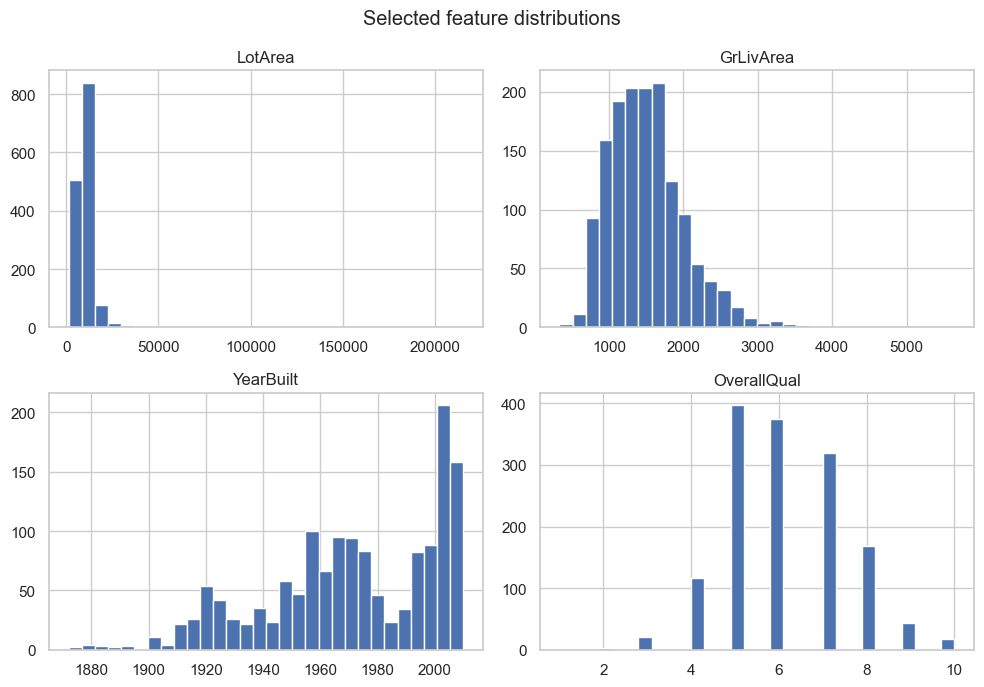

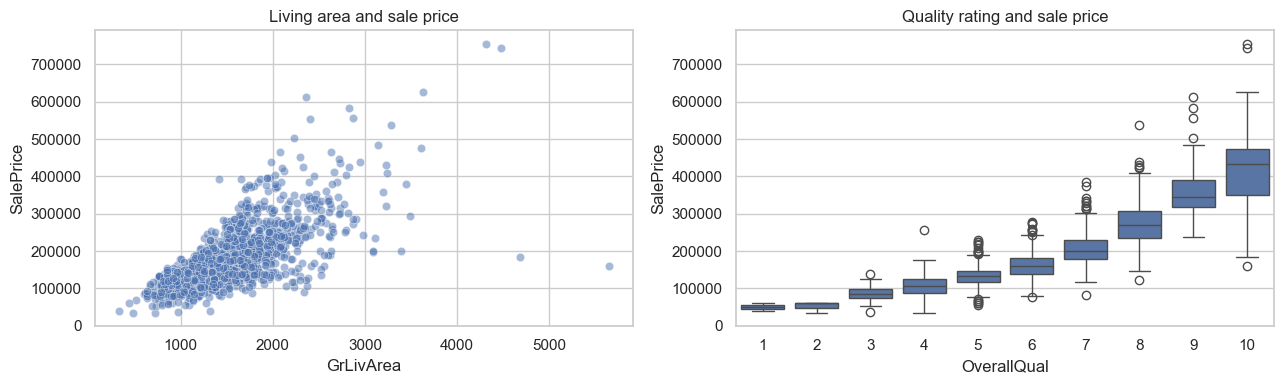

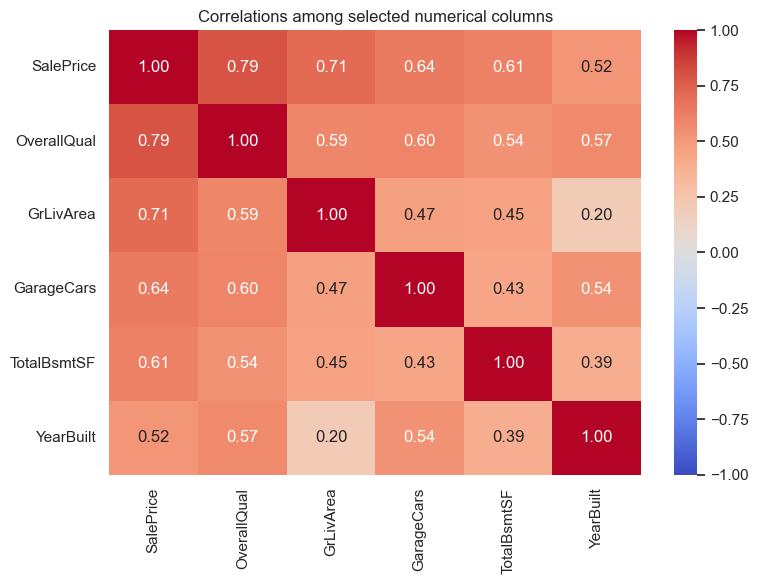

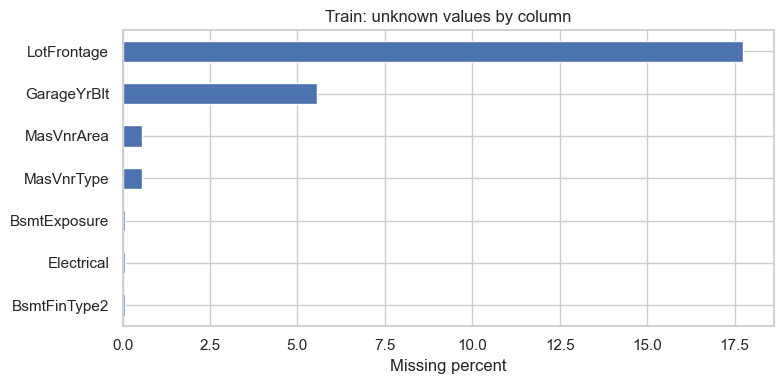

In [8]:
X[["LotArea", "GrLivArea", "YearBuilt", "OverallQual"]].hist(bins=30, figsize=(10, 7))
plt.suptitle("Selected feature distributions")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=train_df, x="GrLivArea", y="SalePrice", alpha=0.5, ax=axes[0])
axes[0].set_title("Living area and sale price")
sns.boxplot(data=train_df, x="OverallQual", y="SalePrice", ax=axes[1])
axes[1].set_title("Quality rating and sale price")
plt.tight_layout()
plt.show()

correlation_columns = ["SalePrice", "OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "YearBuilt"]
plt.figure(figsize=(8, 6))
sns.heatmap(train_df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlations among selected numerical columns")
plt.tight_layout()
plt.show()

unknown_counts = train_missing.loc[train_missing["missing_count"] > 0, "missing_percent"].head(15)
if not unknown_counts.empty:
    unknown_counts.sort_values().plot.barh(figsize=(8, 4), title="Train: unknown values by column")
    plt.xlabel("Missing percent")
    plt.tight_layout()
    plt.show()

## 10. Reviewing data_description.txt before handling missing values
Missing does not always mean unknown. The description defines `NA` as no alley, basement, fireplace, garage, pool, fence, or miscellaneous feature. `MasVnrType` has a `None` category meaning no masonry veneer; its `NA` is unknown.

The loading step preserved documented absence categories and changed unknown tokens to `NaN`. Some basement, garage, and pool attributes have `NA` even when their related measurement is positive. Those contradictions are unknown attributes, not absent structures. For these groups, only a zero related area/count confirms absence; an unknown measurement also leaves the attribute unknown.

The categorical pipeline will label retained absence tokens `Absent` and fill unknown values with the most frequent training category. Numerical gaps receive training medians, including `GarageYrBlt`; this is an introductory baseline, not a claim that an absent garage has a real construction year. No source file is changed.

In [9]:
description = Path("data/data_description.txt").read_text(encoding="utf-8")
# absence_columns was defined during dictionary-based loading.
# Split the description at each feature heading and print relevant entries.
import re
entries = re.split(r"(?m)(?=^[A-Za-z0-9]+:)", description)
for column in absence_columns:
    matches = [entry for entry in entries if entry.startswith(column + ":")]
    assert matches, f"Description entry missing: {column}"
    print(matches[0].strip())
    print()

Alley: Type of alley access to property

       Grvl	Gravel
       Pave	Paved
       NA 	No alley access

BsmtQual: Evaluates the height of the basement

       Ex	Excellent (100+ inches)	
       Gd	Good (90-99 inches)
       TA	Typical (80-89 inches)
       Fa	Fair (70-79 inches)
       Po	Poor (<70 inches
       NA	No Basement

BsmtCond: Evaluates the general condition of the basement

       Ex	Excellent
       Gd	Good
       TA	Typical - slight dampness allowed
       Fa	Fair - dampness or some cracking or settling
       Po	Poor - Severe cracking, settling, or wetness
       NA	No Basement

BsmtExposure: Refers to walkout or garden level walls

       Gd	Good Exposure
       Av	Average Exposure (split levels or foyers typically score average or above)	
       Mn	Mimimum Exposure
       No	No Exposure
       NA	No Basement

BsmtFinType1: Rating of basement finished area

       GLQ	Good Living Quarters
       ALQ	Average Living Quarters
       BLQ	Below Average Living Quarters	
   

## 11. Train-validation split
Hold out 20% of the labeled rows as validation data. A fixed `random_state` makes the split reproducible. Kaggle's unlabeled test data stays separate. Split before learning medians, modes, or encoding categories. We will not combine train, validation, and Kaggle test to fit preprocessing.

In [10]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=42
)
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()
assert "Id" not in X_train and "SalePrice" not in X_train
assert set(X_train.index).isdisjoint(X_valid.index)
assert len(X_train) + len(X_valid) == len(X)
print("Training split:", X_train.shape, "Target:", y_train.shape)
print("Validation split:", X_valid.shape, "Target:", y_valid.shape)
print("Kaggle test:", X_kaggle_test.shape)

Training split: (1168, 79) Target: (1168,)
Validation split: (292, 79) Target: (292,)
Kaggle test: (1459, 79)


## 12. Numerical imputation using median
Imputation replaces missing values. The median is the middle value and is less sensitive to extreme values than the mean. We only define the numerical pipeline here; it learns medians when the full preprocessor is fitted in section 15. `keep_empty_features=True` preserves a column even if it has no observed training values; scikit-learn then uses zero as a fallback.

In [11]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
])

## 13. Categorical imputation using most frequent values
Unknown and contradictory tokens were already converted to `NaN` during loading. First map retained documented `NA`/`None` categories to `Absent`. This fixed rule comes from the description and learns nothing from the rows. Then fill actual unknowns with the most frequent training category (the mode). An entirely empty training column gets an `Unknown` fallback so it remains a string category. `Absent` and `Unknown` have different meanings.

In [12]:
def prepare_categories(frame):
    result = frame.copy()
    for column in result.columns:
        result[column] = result[column].astype(object).where(result[column].notna(), np.nan)
        if column in absence_columns:
            tokens = ["None"] if column == "MasVnrType" else ["NA"]
            result[column] = result[column].replace({token: "Absent" for token in tokens})
    return result

def preserve_empty_categories(frame):
    # Applied after mode imputation; only wholly empty training columns get 0.
    return np.where(frame == 0, "Unknown", frame)

categorical_imputer = SimpleImputer(strategy="most_frequent", keep_empty_features=True)

## 14. One-hot encoding
One-hot encoding creates a 0/1 column for each learned category. For example, neighborhoods become separate indicators rather than arbitrary rankings. `handle_unknown="ignore"` lets a new validation/test category pass safely: its indicators for that feature are all zero. For this small dataset, dense output makes missing-value checks easy; sparse output is more memory-efficient for large datasets.

In [13]:
categorical_pipeline = Pipeline(steps=[
    ("documented_absence", FunctionTransformer(prepare_categories, feature_names_out="one-to-one")),
    ("imputer", categorical_imputer),
    ("empty_column_fallback", FunctionTransformer(preserve_empty_categories, feature_names_out="one-to-one")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

## 15. Preprocessing using Pipeline and ColumnTransformer
A `Pipeline` applies steps in order. `ColumnTransformer` sends numerical columns to one pipeline and categorical columns to another, then combines their results.

**Fit only on `X_train`.** Use `transform` for validation and Kaggle test. No price target enters the preprocessor, and no prediction model is trained. The fitted medians, modes, and category vocabulary all come from the training split.

In [14]:
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
], remainder="drop")

X_train_processed = preprocessor.fit_transform(X_train)
X_valid_processed = preprocessor.transform(X_valid)
X_test_processed = preprocessor.transform(X_kaggle_test)

learned_medians = preprocessor.named_transformers_["numeric"].named_steps["imputer"].statistics_
display(pd.Series(learned_medians, index=numeric_features, name="training_median").head(10))

LotFrontage       70.0
LotArea         9600.0
OverallQual        6.0
OverallCond        5.0
YearBuilt       1972.0
YearRemodAdd    1994.0
MasVnrArea         0.0
BsmtFinSF1       384.5
BsmtFinSF2         0.0
BsmtUnfSF        480.0
Name: training_median, dtype: float64

## 16. Verifying the transformed data shapes and remaining missing values
Encoding increases the number of columns. All three datasets must have the same transformed feature count, retain their row counts, and contain no missing or infinite values. These assertions stop execution if a check fails. Original `Id` columns and prices are still preserved in the original tables. We finish with prepared arrays in memory; no cleaned CSV, predictions, or model files are written.

In [15]:
feature_names = preprocessor.get_feature_names_out()
for name, original, processed in [
    ("Training", X_train, X_train_processed),
    ("Validation", X_valid, X_valid_processed),
    ("Kaggle test", X_kaggle_test, X_test_processed),
]:
    missing_count = int(pd.isna(processed).sum())
    print(f"{name}: {original.shape} -> {processed.shape}; missing values = {missing_count}")
    assert processed.shape[0] == original.shape[0]
    assert processed.shape[1] == len(feature_names)
    assert missing_count == 0
    assert np.isfinite(processed).all()

assert "Id" in train_df and "Id" in test_df
assert "SalePrice" in train_df
assert not any(name.endswith("__Id") or name.endswith("__SalePrice") for name in feature_names)
display(pd.DataFrame(X_train_processed[:5], columns=feature_names, index=X_train.index[:5]))
print("All preprocessing checks passed. No prediction model has been trained.")

Training: (1168, 79) -> (1168, 314); missing values = 0
Validation: (292, 79) -> (292, 314); missing values = 0
Kaggle test: (1459, 79) -> (1459, 314); missing values = 0


,numeric__LotFrontage,numeric__LotArea,numeric__OverallQual,numeric__OverallCond,numeric__YearBuilt,numeric__YearRemodAdd,numeric__MasVnrArea,...,categorical__SaleType_WD,categorical__SaleCondition_Abnorml,categorical__SaleCondition_AdjLand,categorical__SaleCondition_Alloca,categorical__SaleCondition_Family,categorical__SaleCondition_Normal,categorical__SaleCondition_Partial
254,70.0,8400.0,5.0,6.0,1957.0,1957.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1066,59.0,7837.0,6.0,7.0,1993.0,1994.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0
638,67.0,8777.0,5.0,7.0,1910.0,1950.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0
799,60.0,7200.0,5.0,7.0,1937.0,1950.0,252.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0
380,50.0,5000.0,5.0,6.0,1924.0,1950.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0


All preprocessing checks passed. No prediction model has been trained.


### What you have learned
You inspected the data, interpreted documented absence, kept IDs out of features, split labeled rows, and fitted an imputation/encoding pipeline only on training rows. The three processed arrays are ready for a future modeling lesson. Keep validation data held out when you later compare models. For cross-validation, place preprocessing inside each fold's model pipeline so it is fitted again on that fold's training rows.